# Figure 4

![Full Figure](../figures/fig04_FULL.png)

## Code for Figure 4: violation × stimulus interactions

**Goal:** Reproduce post-violation performance, interaction-model weights/intuition, and simulated psychometrics from the submitted Figure 4 notebook, with Revision 1 label/range updates on panels C–E.

| Panel | Content | Inputs |
|---|---|---|
| A | Hit rate by previous-violation history | `load_trials_df` |
| B | Interaction intuition + binary/filtered GLM weights | demo intuition table; `scripts/fit_fig04.py` summaries |
| C | Simulated psychometric functions (δ = −2…2) | binary interaction fit via `simulate_psychometrics` |
| D | Stimulus sensitivity (slope at δ = 0) | same |
| E | Combined lapse rate | same |

**Outputs:** `figures/fig04a_post_violation_performance.png`, `figures/fig04b_prev_violation_intuition.png`, `figures/fig04b_stimulus_a_intuition.png`, `figures/fig04b_interaction_intuition.png`, `figures/fig04b_binary_interaction_weights.png`, `figures/fig04b_filtered_interaction_weights.png`, `figures/fig04c_simulated_psychometrics.png`, `figures/fig04d_stimulus_sensitivity.png`, `figures/fig04e_combined_lapse_rate.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from violations_glm.config import (
    HIT_COLOR,
    MULTI_CHOICE_PALETTE,
    PREV_VIOLATION_COLOR,
    VIOLATION_COLOR,
)
from violations_glm.features import previous_violation
from violations_glm.io import load_model_summary, load_trials_df
from violations_glm.plotting import configure_publication_dpi, save_figure
from violations_glm.psychometrics import simulate_psychometrics
from violations_glm.stats import within_subject_test
from violations_glm.summaries import best_fits, unpack_weights

configure_publication_dpi()
sns.set_context("talk")

In [2]:
BINARY_FIT = "2025_07_22_fig4_fit_binary_prev_viol_stim_intrx_n_rs47"
FILTERED_FIT = "2025_07_22_fig4_fit_filtered_prev_viol_stim_intrx_n_rs47"
WEIGHT_YMIN, WEIGHT_YMAX = -2.1, 2.1
PSYCH_PALETTE = ["k", VIOLATION_COLOR]
PSYCH_STYLE_ORDER = [1, 0]
CONDITION_LABELS = {0: "Not Prev Violation", 1: "Prev Violation"}

BINARY_FEATURE_ORDER = [
    "s_a",
    "sa_x_prev_viol",
    "s_b",
    "sb_x_prev_viol",
    "prev_violation",
    "prev_stim_avg",
    "prev_correct",
    "prev_choice",
]
BINARY_FEATURE_LABELS = [
    "Stim A",
    "Stim A x\nPrev Violation",
    "Stim B",
    "Stim B x\nPrev Violation",
    "Prev Violation",
    "Prev Stim Avg",
    "Prev Correct",
    "Prev Choice",
]
FILTERED_FEATURE_ORDER = [
    "s_a",
    "sa_x_prev_viol",
    "s_b",
    "sb_x_prev_viol",
    "filt_prev_violation",
    "prev_stim_avg",
    "prev_correct",
    "prev_choice",
]
FILTERED_FEATURE_LABELS = [
    "Stim A",
    "Stim A x\nPrev Violation",
    "Stim B",
    "Stim B x\nPrev Violation",
    "Filterted\nPrev Violation",
    "Prev Stim Avg",
    "Prev Correct",
    "Prev Choice",
]

# Submitted demo sequence for panel-B intuition (demo_intuition_data.csv).
INTUITION = pd.DataFrame(
    {
        "trial": np.arange(1, 11),
        "violation": [0, 1, 0, 0, 0, 0, 1, 0, 0, 0],
        "prev_violation": [0, 0, 1, 0, 0, 0, 0, 1, 0, 0],
        "s_a": [
            -1.5861895471831726,
            -0.7495552571038326,
            -1.5861895471831726,
            -0.7495552571038326,
            0.08707903297550743,
            0.9237133230548474,
            0.08707903297550743,
            0.9237133230548474,
            0.9237133230548474,
            1.7603476131341875,
        ],
        "s_a_x_prev_violation": [
            -0.0,
            -0.0,
            -1.5861895471831726,
            -0.0,
            0.0,
            0.0,
            0.0,
            0.9237133230548474,
            0.0,
            0.0,
        ],
    }
)

binary_fits = load_model_summary(BINARY_FIT)
filtered_fits = load_model_summary(FILTERED_FIT)
curves, metrics = simulate_psychometrics(binary_fits)
metrics_melted = pd.melt(
    metrics.rename(
        columns={
            "previous_violation": "prev_violation",
            "slope_at_zero": "slope",
            "combined_lapse_rate": "combined_lapse",
        }
    ),
    id_vars=["animal_id", "prev_violation"],
    value_vars=["slope", "combined_lapse"],
    var_name="metric",
    value_name="value",
)

## Panel A — Performance after a violation

Hit rates are first averaged within session and history condition, then within animal. Model fits are not used here.

5210
  animal_id  prev_violation       hit  percent_correct
0      W051               0  0.802936        80.293573
1      W051               1  0.766545        76.654478
2      W060               0  0.830631        83.063119
3      W060               1  0.783092        78.309221
4      W065               0  0.776971        77.697107
16 subjects/replicates:
 • Not Prev Violation: mean = 0.813, SD = 0.041
 • Prev Violation: mean = 0.778, SD = 0.035

Shapiro–Wilk: W = 0.891, p = 0.057
Paired t-test: t = -6.120733149022932, p = 1.957957918672428e-05


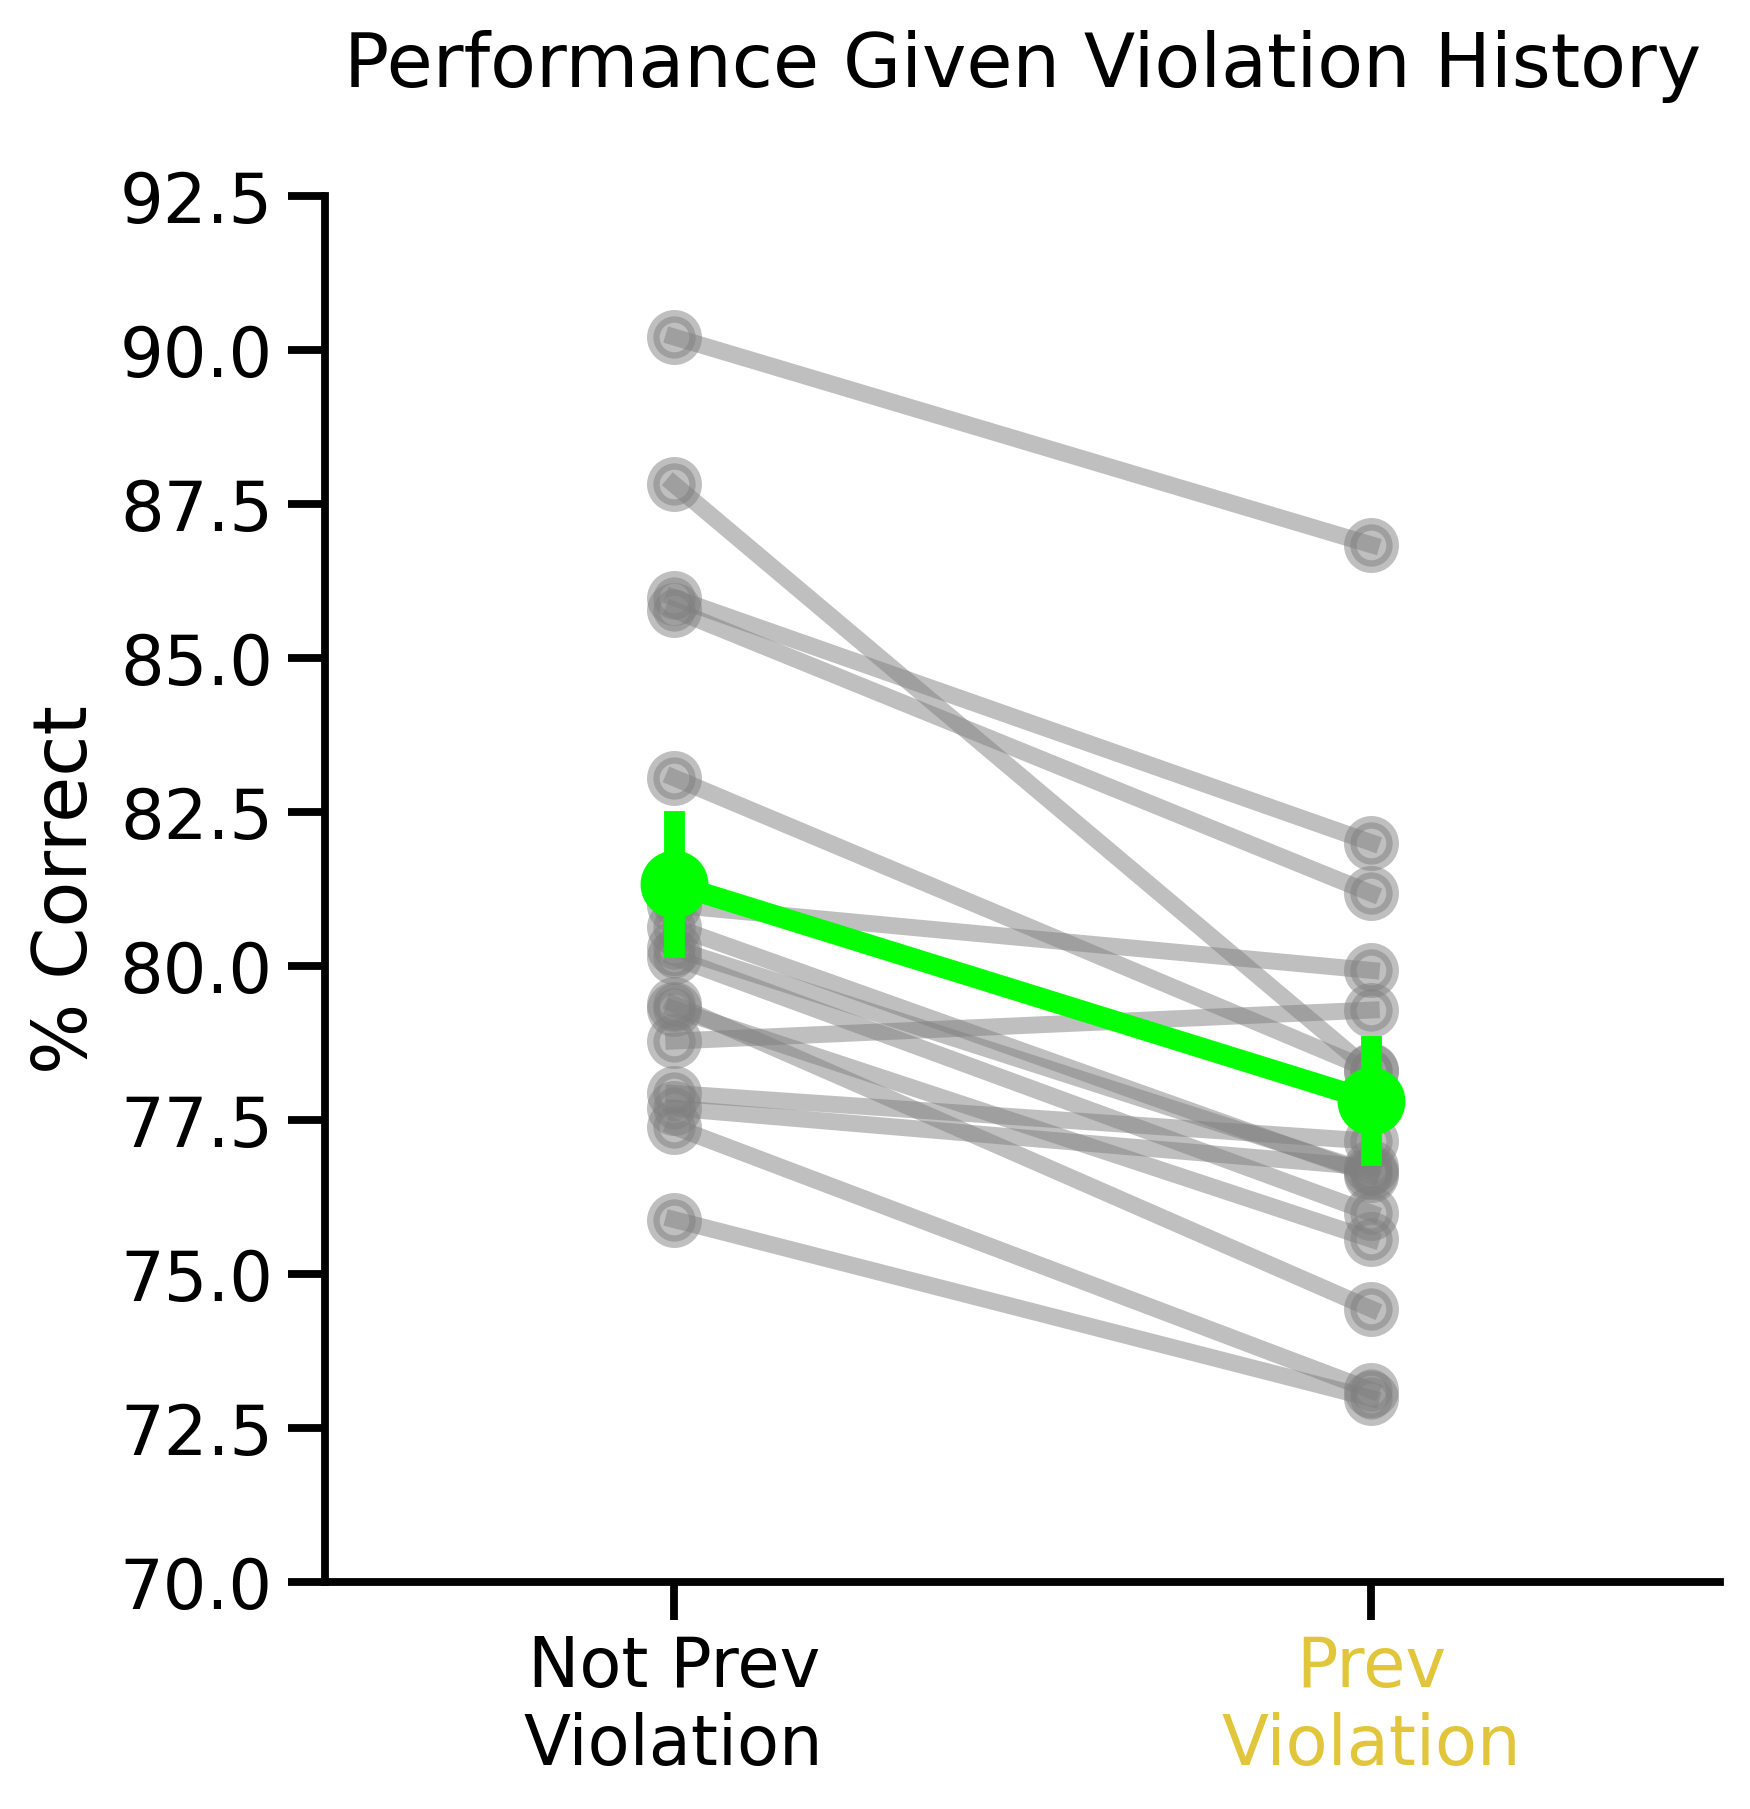

In [3]:
trials = load_trials_df().copy()
trials["prev_violation"] = previous_violation(trials)
print(len(trials.groupby(["animal_id", "session"])))

hit_rates = (
    trials.groupby(["animal_id", "session", "prev_violation"],
                   as_index=False)["hit"]
    .mean()
    .groupby(["animal_id", "prev_violation"], as_index=False)["hit"]
    .mean()
)
hit_rates["percent_correct"] = hit_rates["hit"] * 100
print(hit_rates.head())

fig, ax = plt.subplots(figsize=(6, 6))
sns.despine()
sns.pointplot(
    data=hit_rates,
    x="prev_violation",
    y="percent_correct",
    hue="animal_id",
    ax=ax,
    palette=["gray"] * 16,
    alpha=0.5,
)
sns.pointplot(
    data=hit_rates,
    x="prev_violation",
    y="percent_correct",
    ax=ax,
    color=HIT_COLOR,
    errorbar="se",
    lw=5,
)
ax.get_legend().remove()
ax.set_xticks(range(2))
ax.set_xticklabels(["Not Prev\nViolation", "Prev\nViolation"])
for label, color in zip(ax.get_xticklabels(), ["k", VIOLATION_COLOR]):
    label.set_color(color)
ax.set(ylim=(70, 92.5), ylabel="% Correct", xlabel="")
ax.set_title("Performance Given Violation History\n")
save_figure(fig, "fig04a_post_violation_performance")

hit_stats = within_subject_test(
    hit_rates,
    subject_col="animal_id",
    condition_col="prev_violation",
    value_col="hit",
    condition_labels=CONDITION_LABELS,
)

## Panel B — Interaction intuition and GLM weights

Fits come from [`scripts/fit_fig04.py`](../scripts/fit_fig04.py) (binary and filtered previous-violation × stimulus interaction models).

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig04b_filtered_interaction_weights.png')

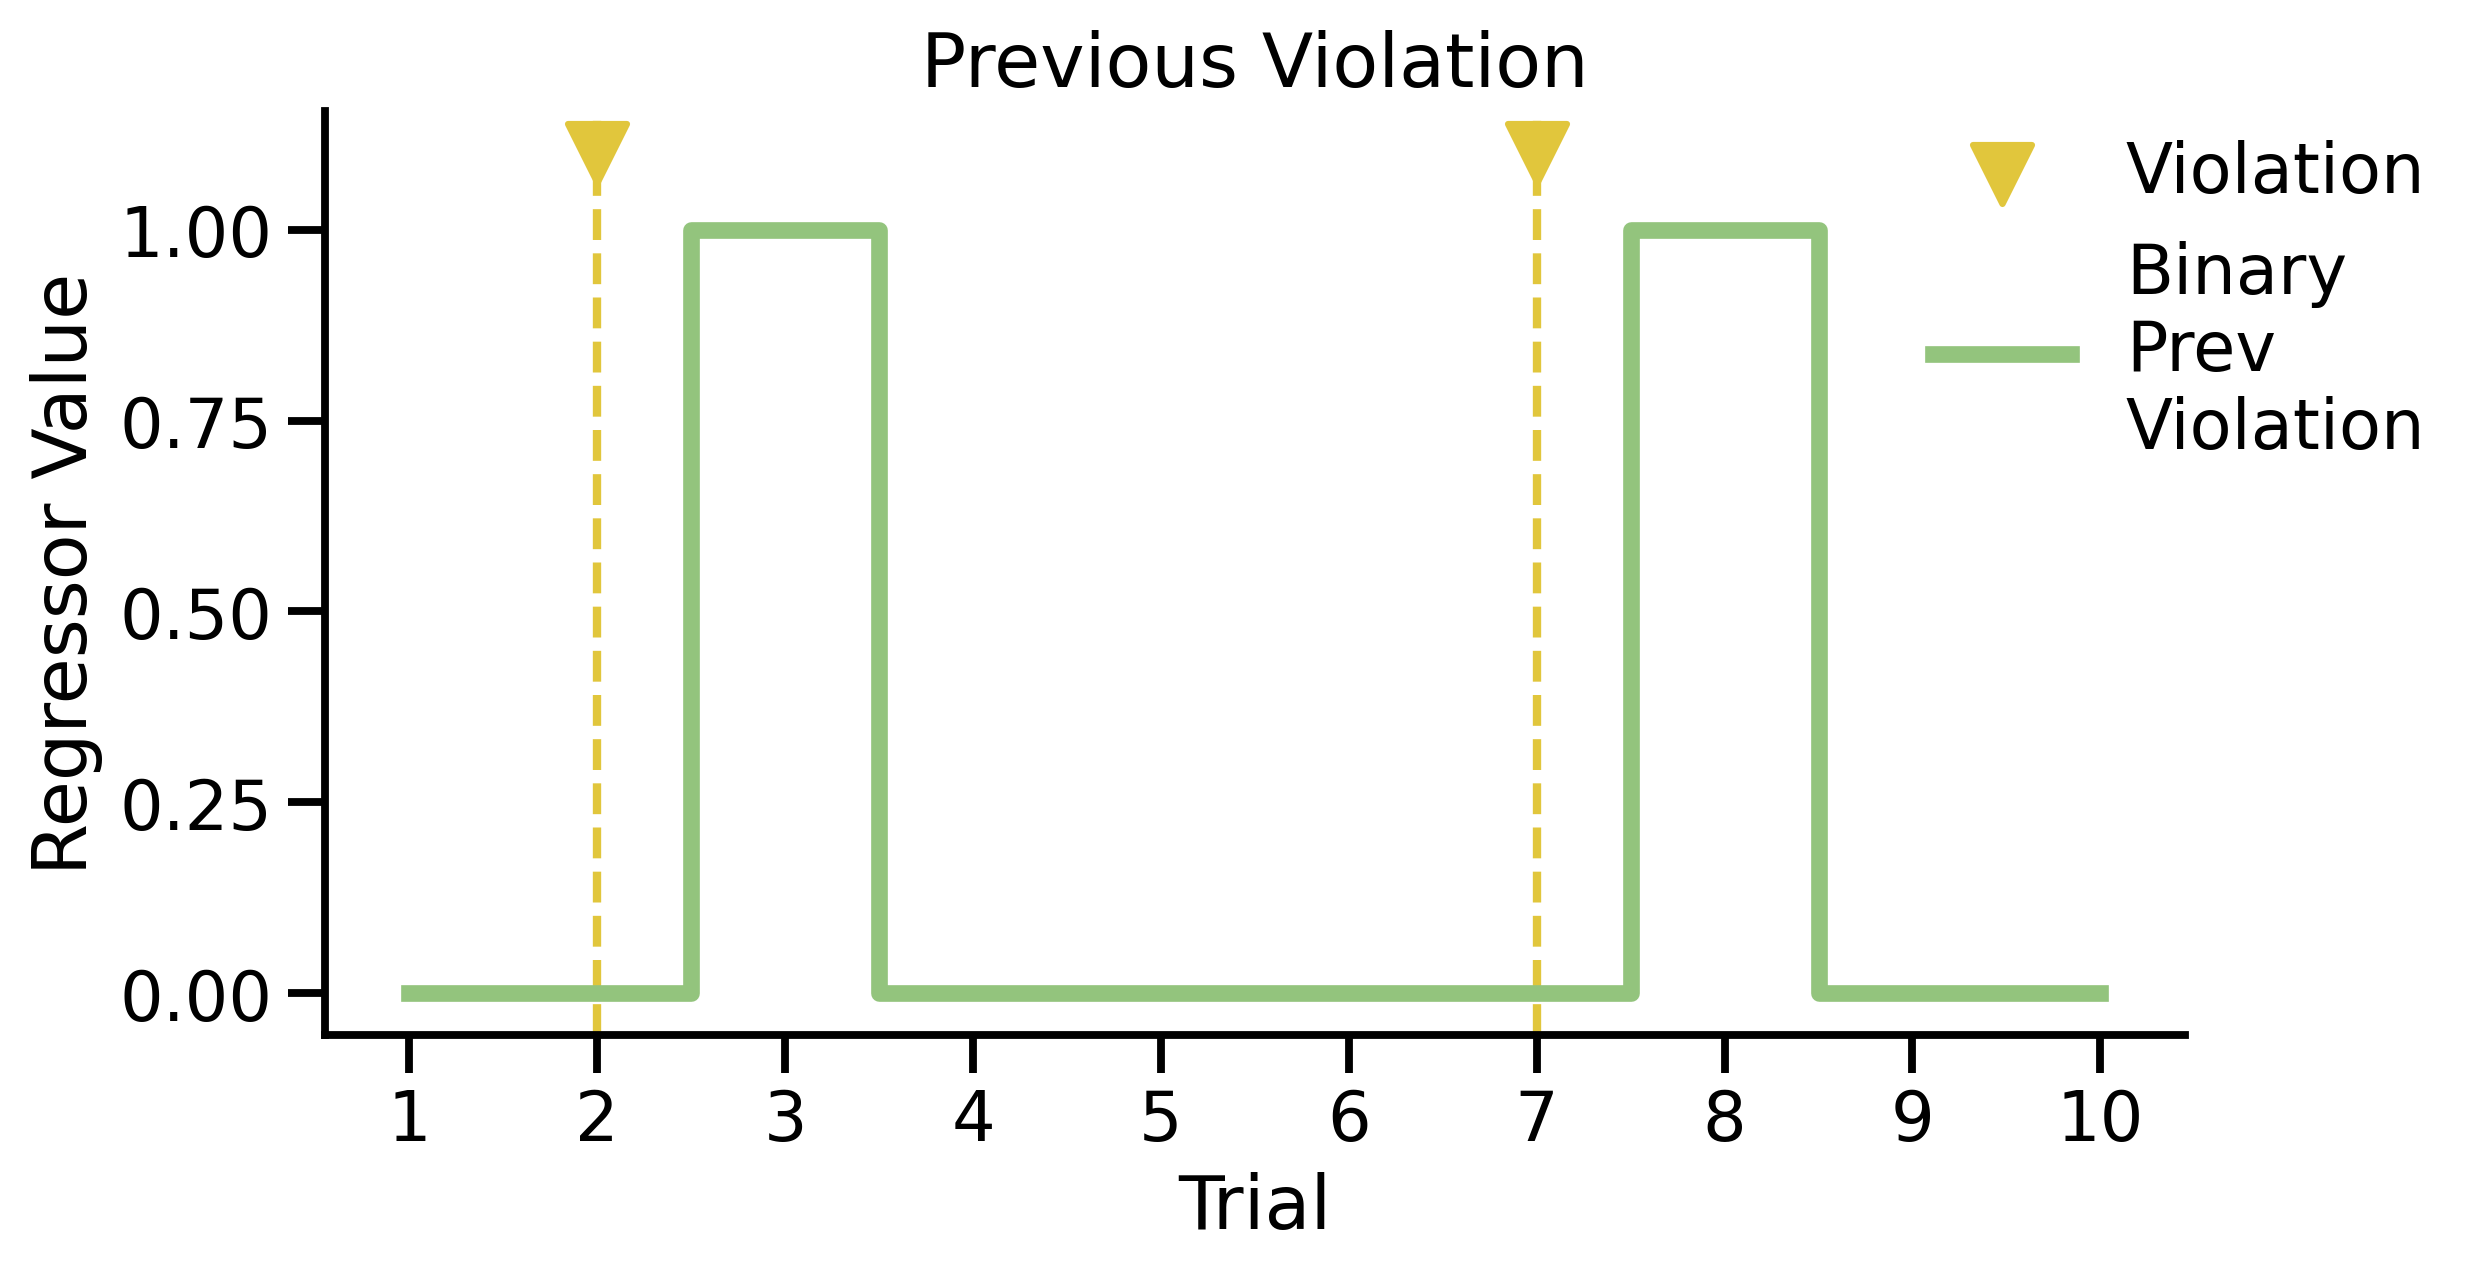

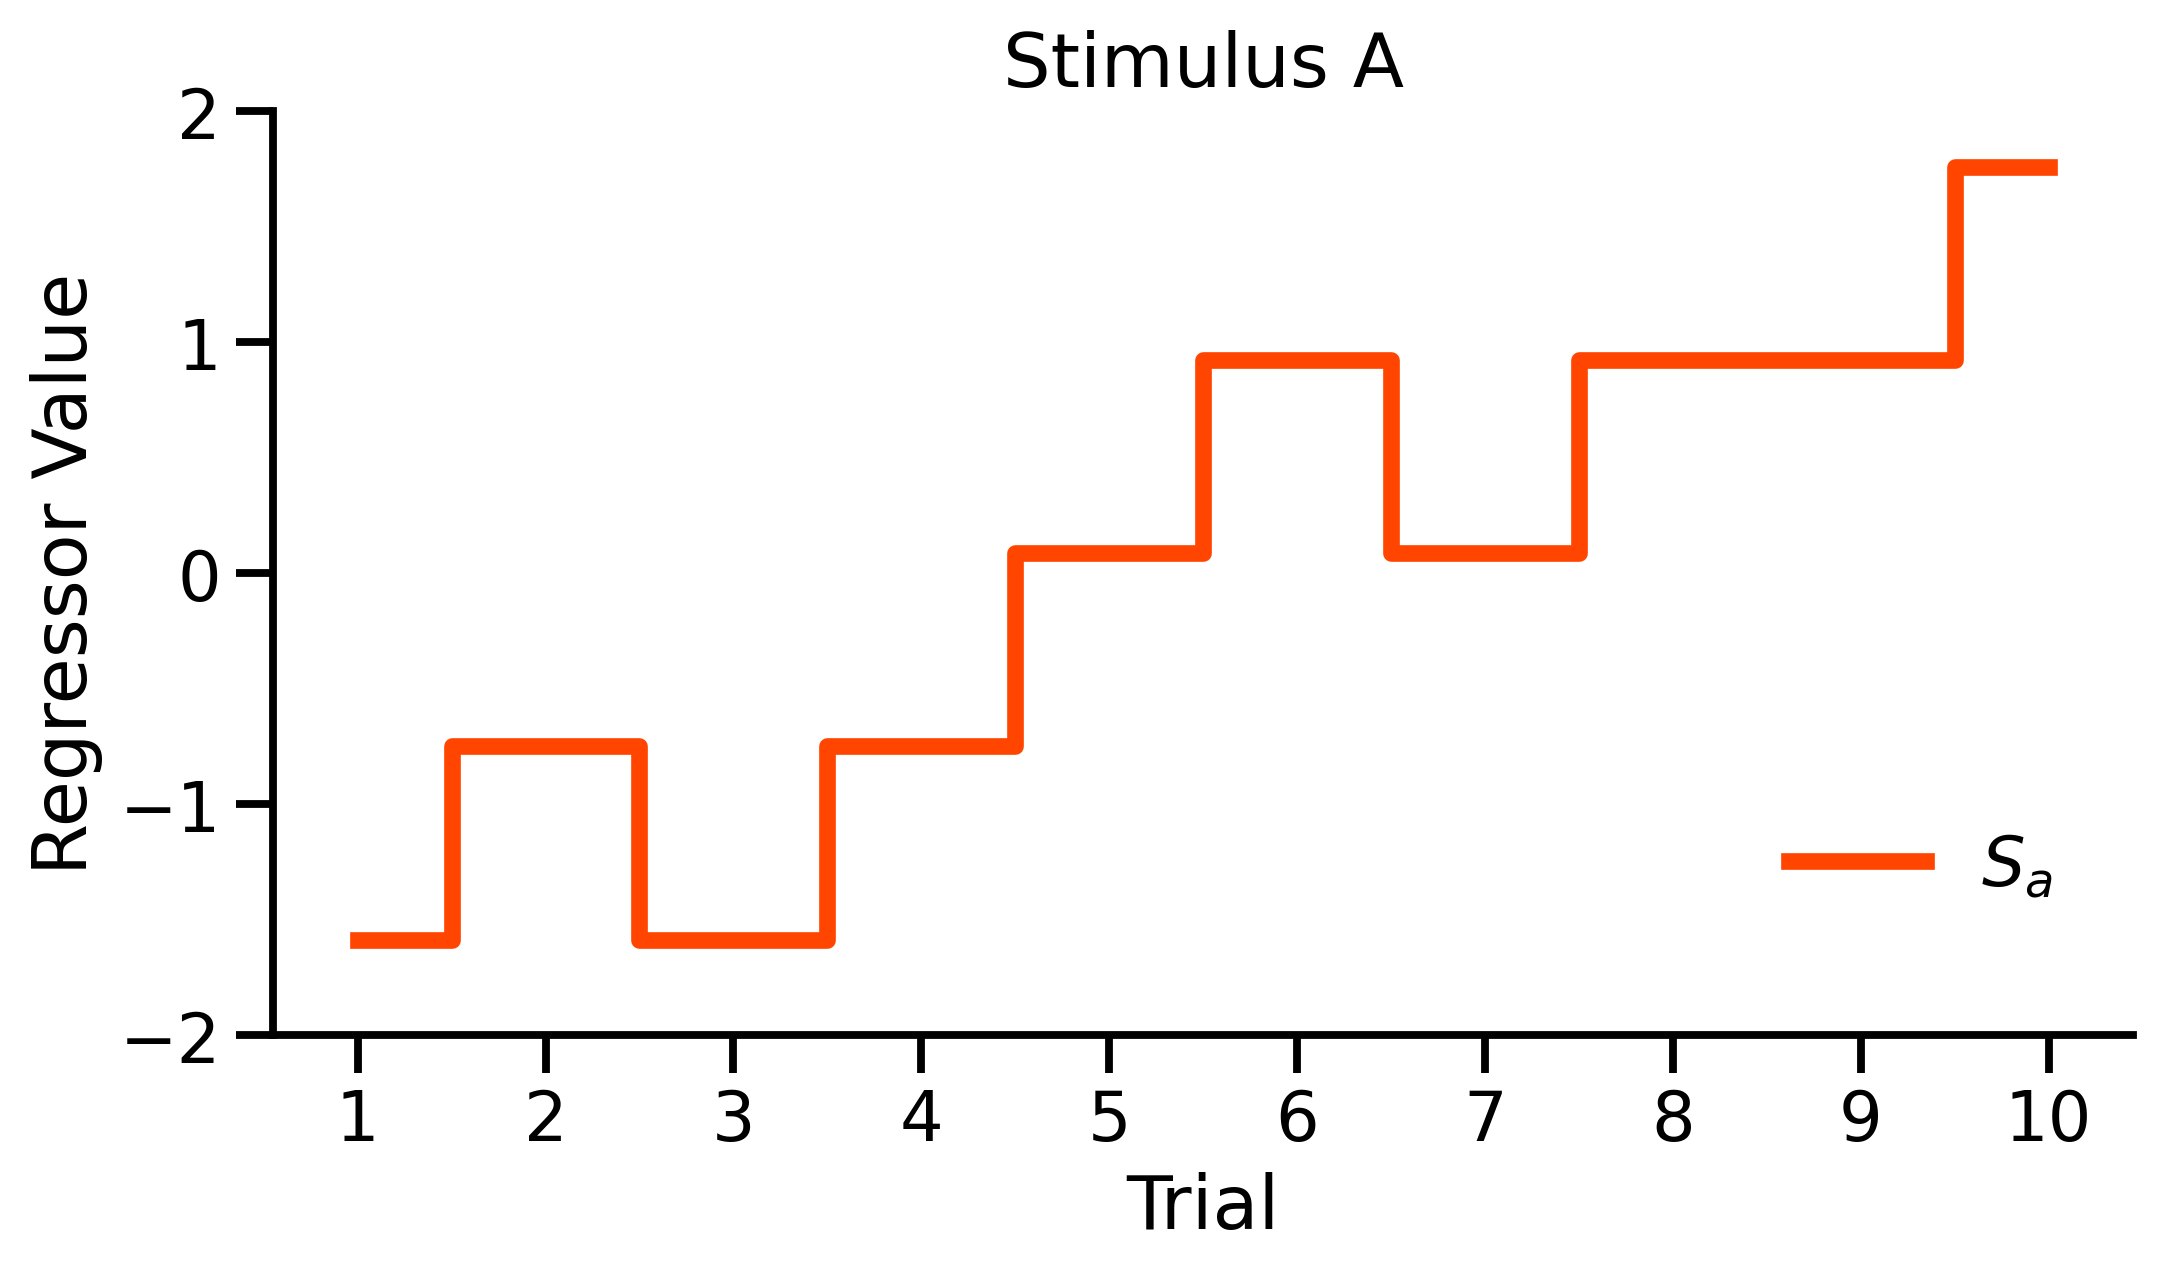

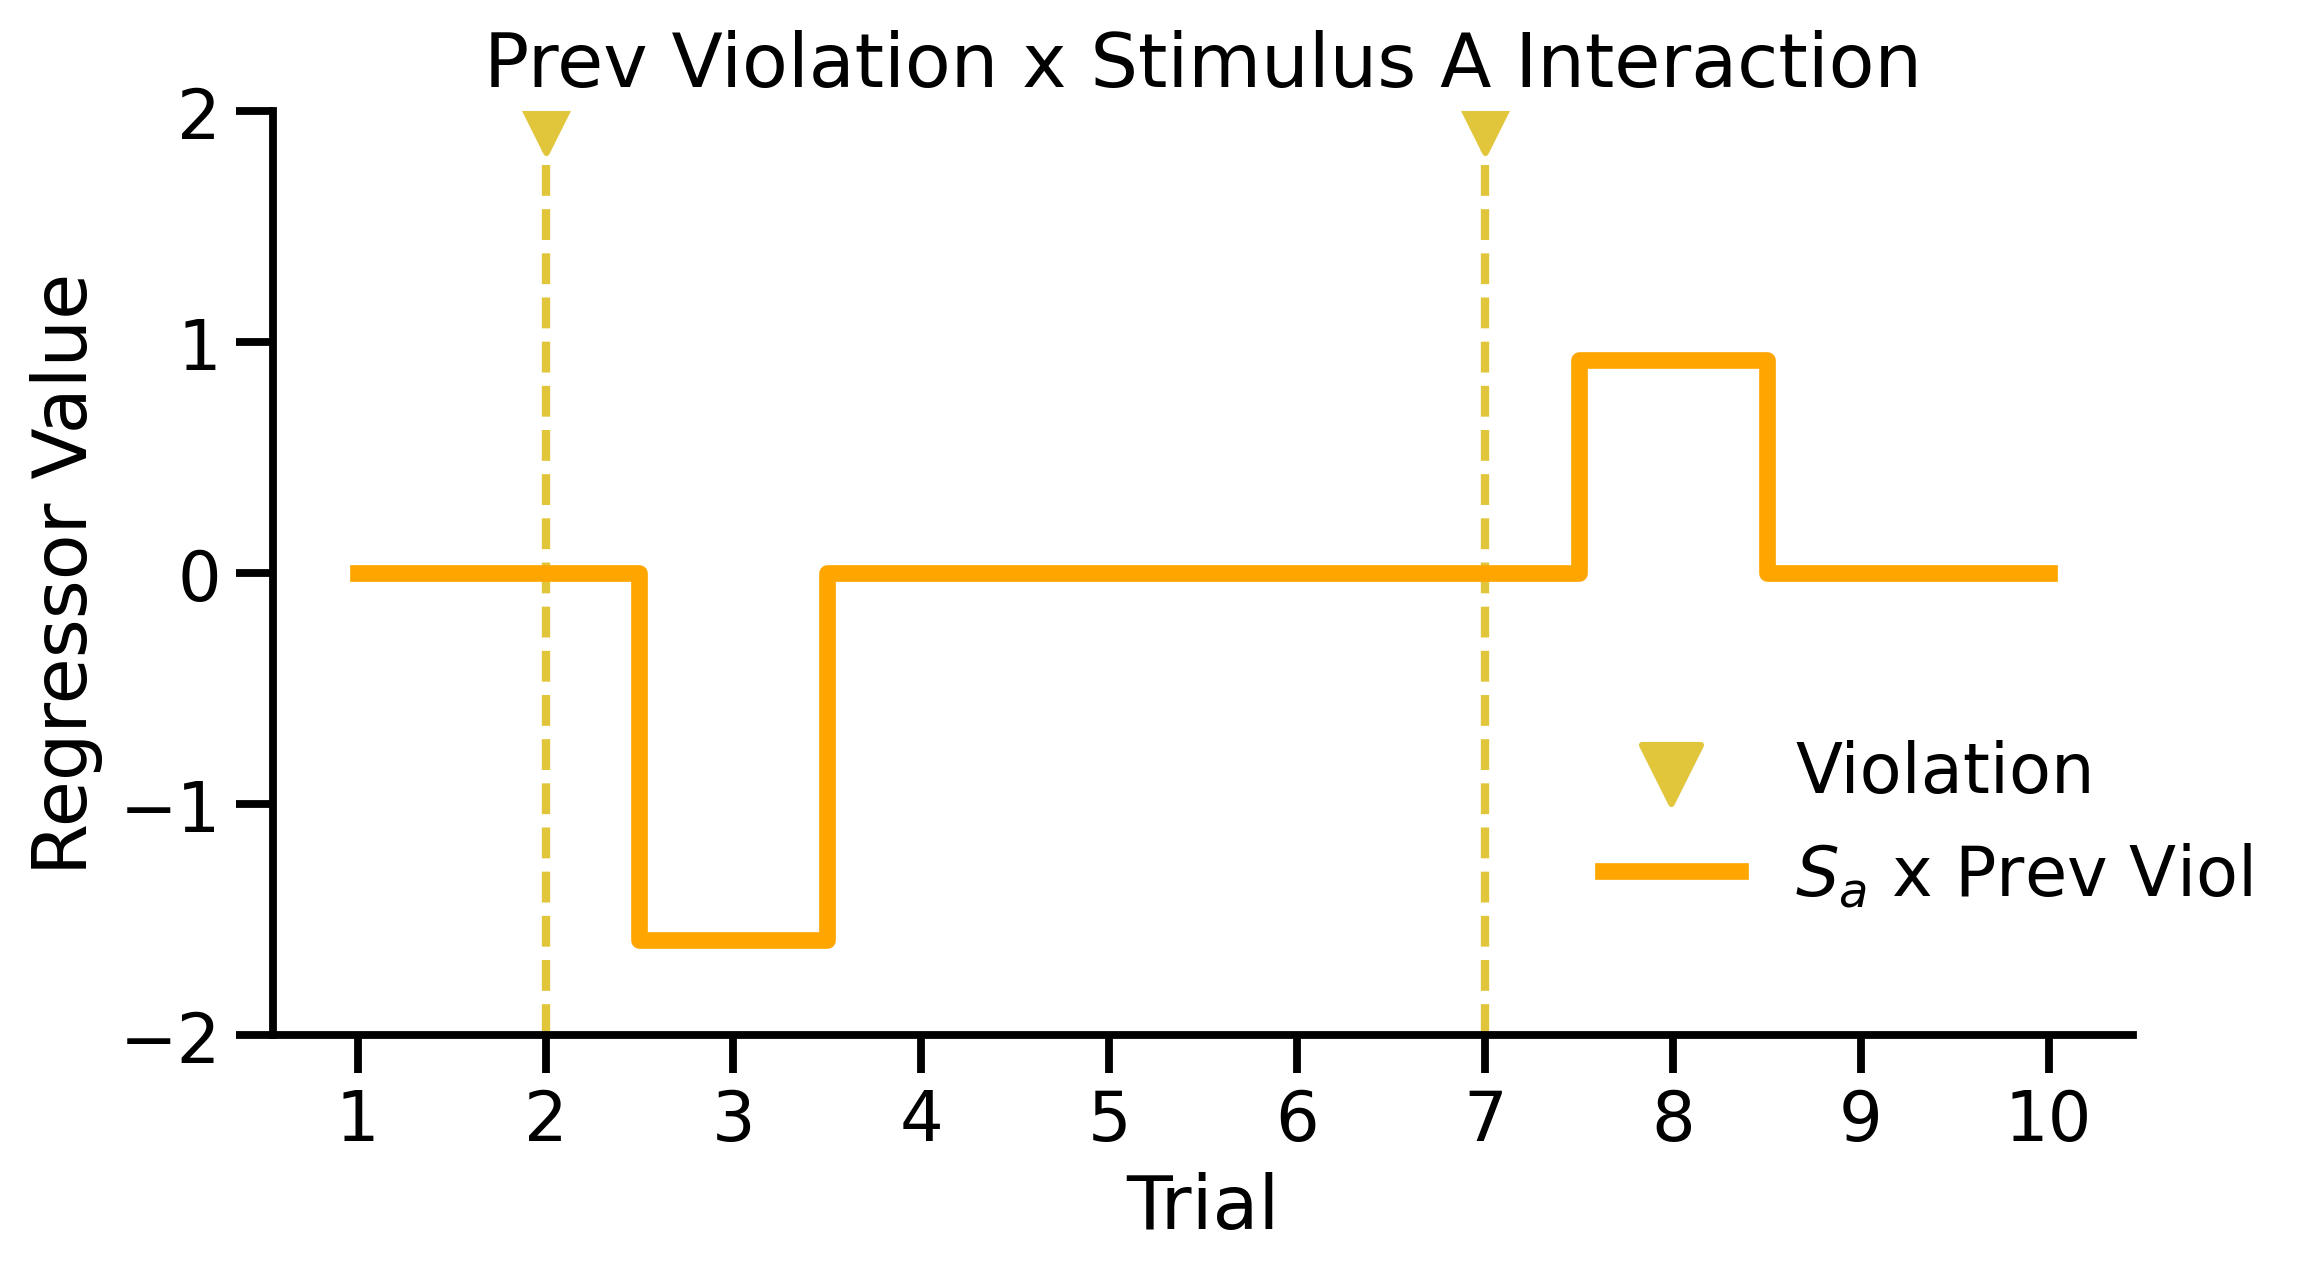

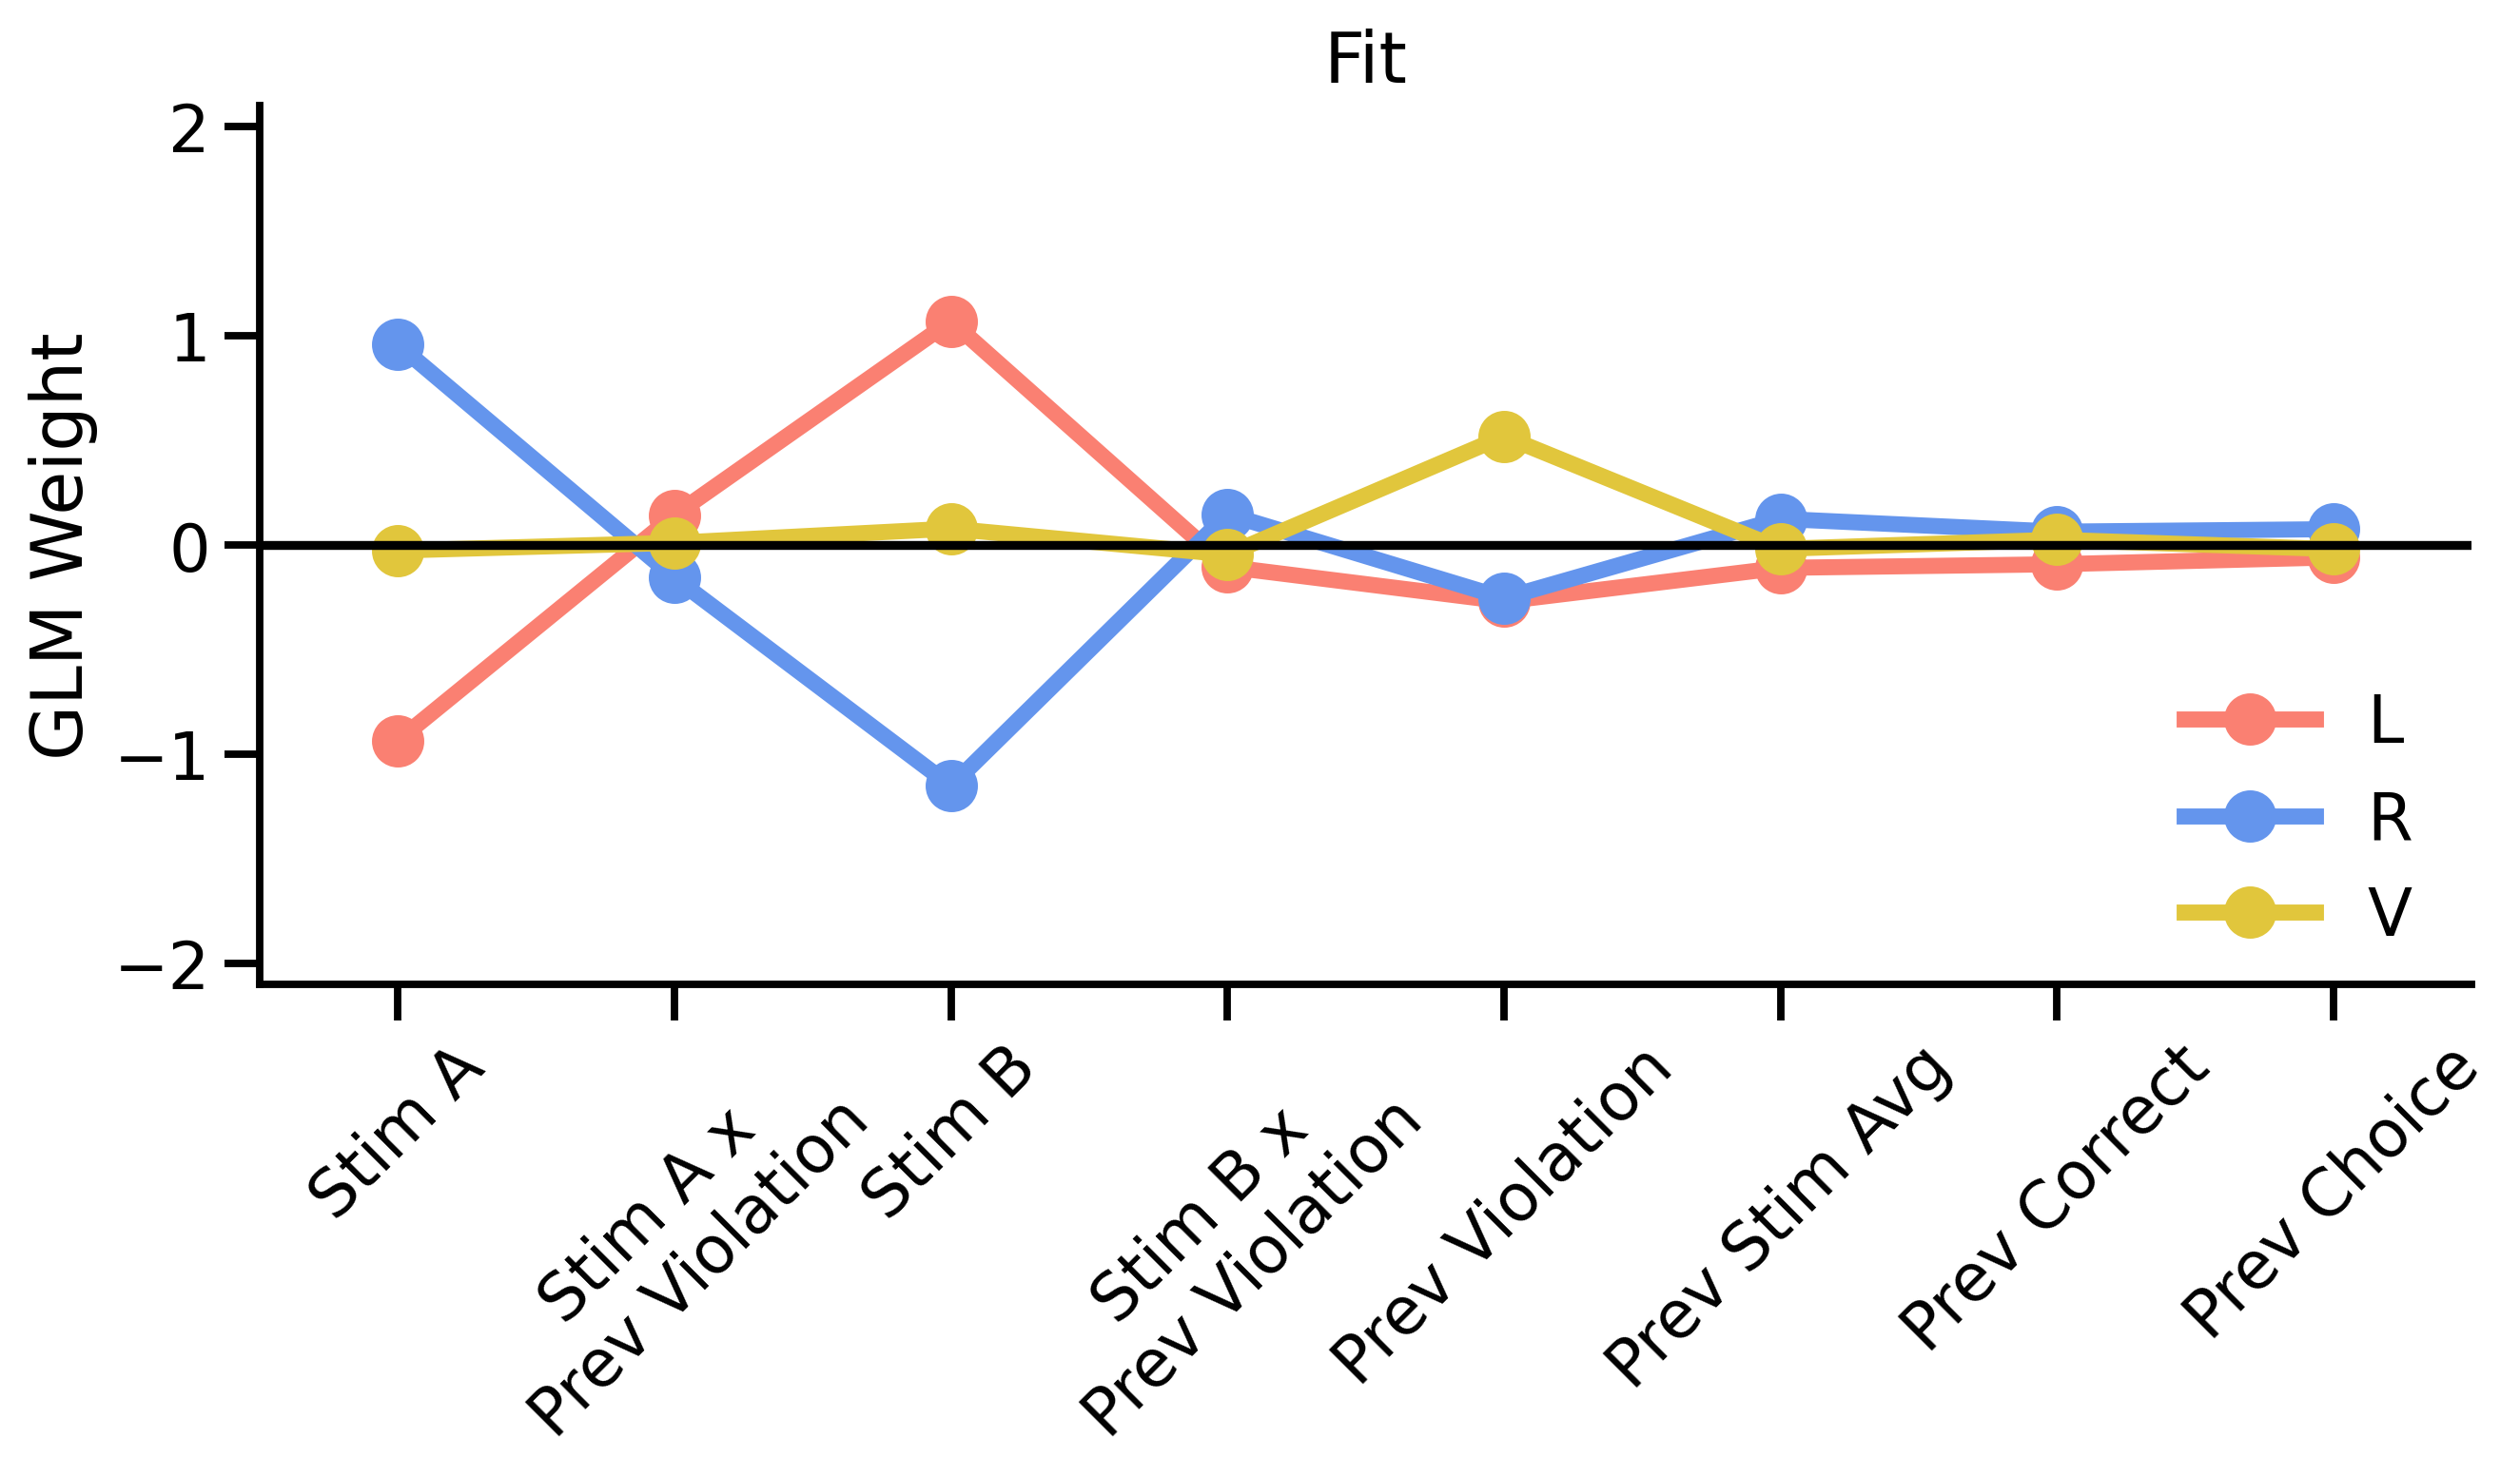

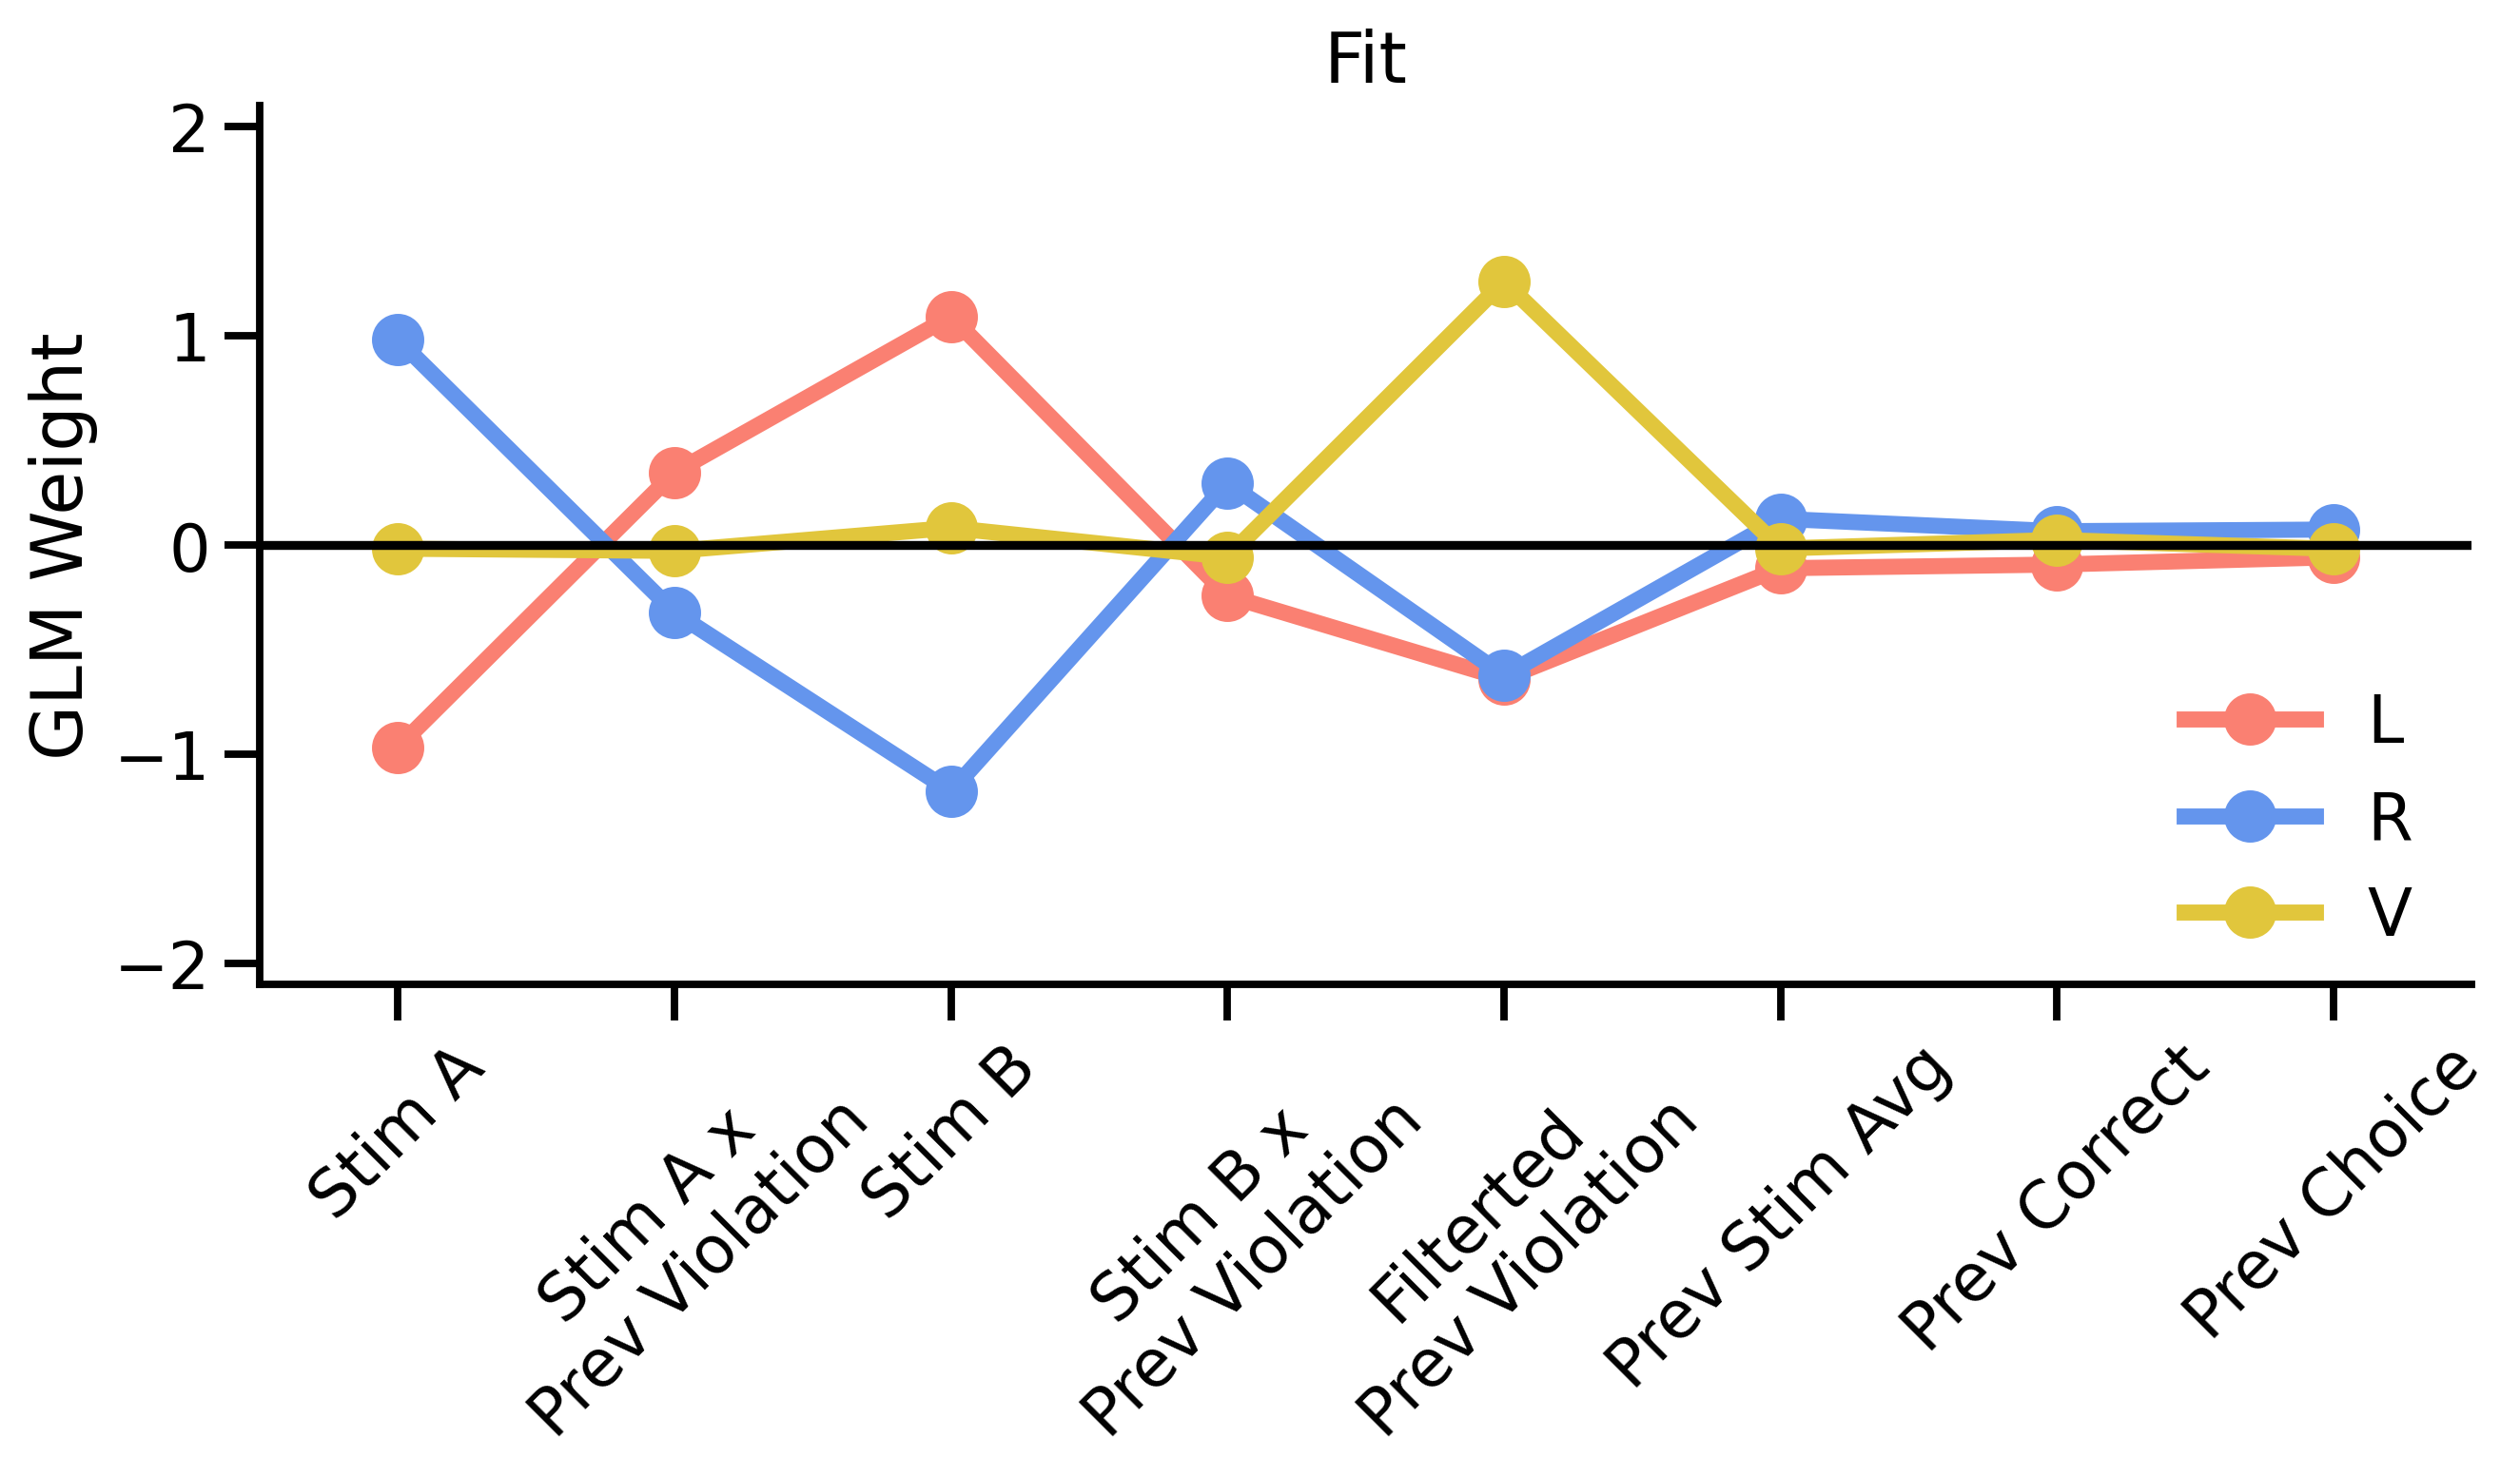

In [4]:
violations = INTUITION.query("violation == 1")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    violations["trial"],
    violations["violation"] + 0.1,
    color=VIOLATION_COLOR,
    marker="v",
    label="Violation",
    s=200,
)
for trial in violations["trial"]:
    ax.axvline(x=trial, ymax=1.0, color=VIOLATION_COLOR,
               linestyle="--", linewidth=2)
sns.lineplot(
    x=INTUITION["trial"],
    y=INTUITION["prev_violation"],
    drawstyle="steps-mid",
    label="Binary\nPrev\nViolation",
    ax=ax,
    color=PREV_VIOLATION_COLOR,
    linewidth=4,
)
ax.legend(bbox_to_anchor=(0.85, 1), loc="upper left",
          borderaxespad=0.0, frameon=False)
ax.set(ylabel="Regressor Value", xlabel="Trial", title="Previous Violation")
ax.set_xticks(np.arange(1, 11))
sns.despine()
save_figure(fig, "fig04b_prev_violation_intuition")

fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(
    x=INTUITION["trial"],
    y=INTUITION["s_a"],
    drawstyle="steps-mid",
    label="$S_a$",
    ax=ax,
    color="orangered",
    linewidth=4,
)
ax.legend(bbox_to_anchor=(0.8, 0.25), loc="upper left",
          borderaxespad=0.0, frameon=False)
ax.set(ylabel="Regressor Value", xlabel="Trial",
       title="Stimulus A", ylim=(-2, 2))
ax.set_xticks(np.arange(1, 11))
sns.despine()
save_figure(fig, "fig04b_stimulus_a_intuition")

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    violations["trial"],
    violations["violation"] + 0.95,
    color=VIOLATION_COLOR,
    marker="v",
    label="Violation",
    s=200,
)
for trial in violations["trial"]:
    ax.axvline(x=trial, ymax=1.0, color=VIOLATION_COLOR,
               linestyle="--", linewidth=2)
sns.lineplot(
    x=INTUITION["trial"],
    y=INTUITION["s_a_x_prev_violation"],
    drawstyle="steps-mid",
    label="$S_a$ x Prev Viol",
    ax=ax,
    color="orange",
    linewidth=4,
)
ax.legend(bbox_to_anchor=(0.7, 0.35), borderaxespad=0.0, frameon=False)
ax.set(
    ylabel="Regressor Value",
    xlabel="Trial",
    title="Prev Violation x Stimulus A Interaction",
    ylim=(-2, 2),
)
ax.set_xticks(np.arange(1, 11))
sns.despine()
save_figure(fig, "fig04b_interaction_intuition")

binary_weights = unpack_weights(
    best_fits(binary_fits)).query("feature != 'bias'")
binary_weights["feature"] = pd.Categorical(
    binary_weights["feature"], categories=BINARY_FEATURE_ORDER, ordered=True
)
fig, ax = plt.subplots(figsize=(10, 4))
sns.pointplot(
    data=binary_weights,
    x="feature",
    y="weight",
    hue="weight_class",
    palette=MULTI_CHOICE_PALETTE,
    errorbar=None,
    ax=ax,
)
ax.axhline(0, color="black")
ax.legend(bbox_to_anchor=(1, 0.4), frameon=False)
ax.set_xticks(range(len(BINARY_FEATURE_LABELS)))
ax.set_xticklabels(BINARY_FEATURE_LABELS, rotation=45, ha="center")
ax.set(xlabel="", ylabel="GLM Weight", title="Fit",
       ylim=(WEIGHT_YMIN, WEIGHT_YMAX))
sns.despine(ax=ax)
save_figure(fig, "fig04b_binary_interaction_weights")

filtered_weights = unpack_weights(
    best_fits(filtered_fits)).query("feature != 'bias'")
filtered_weights["feature"] = pd.Categorical(
    filtered_weights["feature"], categories=FILTERED_FEATURE_ORDER, ordered=True
)
fig, ax = plt.subplots(figsize=(10, 4))
sns.pointplot(
    data=filtered_weights,
    x="feature",
    y="weight",
    hue="weight_class",
    palette=MULTI_CHOICE_PALETTE,
    errorbar=None,
    ax=ax,
)
ax.axhline(0, color="black")
ax.legend(bbox_to_anchor=(1, 0.4), frameon=False)
ax.set_xticks(range(len(FILTERED_FEATURE_LABELS)))
ax.set_xticklabels(FILTERED_FEATURE_LABELS, rotation=45, ha="center")
ax.set(xlabel="", ylabel="GLM Weight", title="Fit",
       ylim=(WEIGHT_YMIN, WEIGHT_YMAX))
sns.despine(ax=ax)
save_figure(fig, "fig04b_filtered_interaction_weights")

## Panel C — Simulated psychometric functions

Curves are simulated from the **binary** interaction model (`scripts/fit_fig04.py`). Revision 1 sets the displayed δ range to −2…2 and updates axis titles/labels.

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig04c_simulated_psychometrics.png')

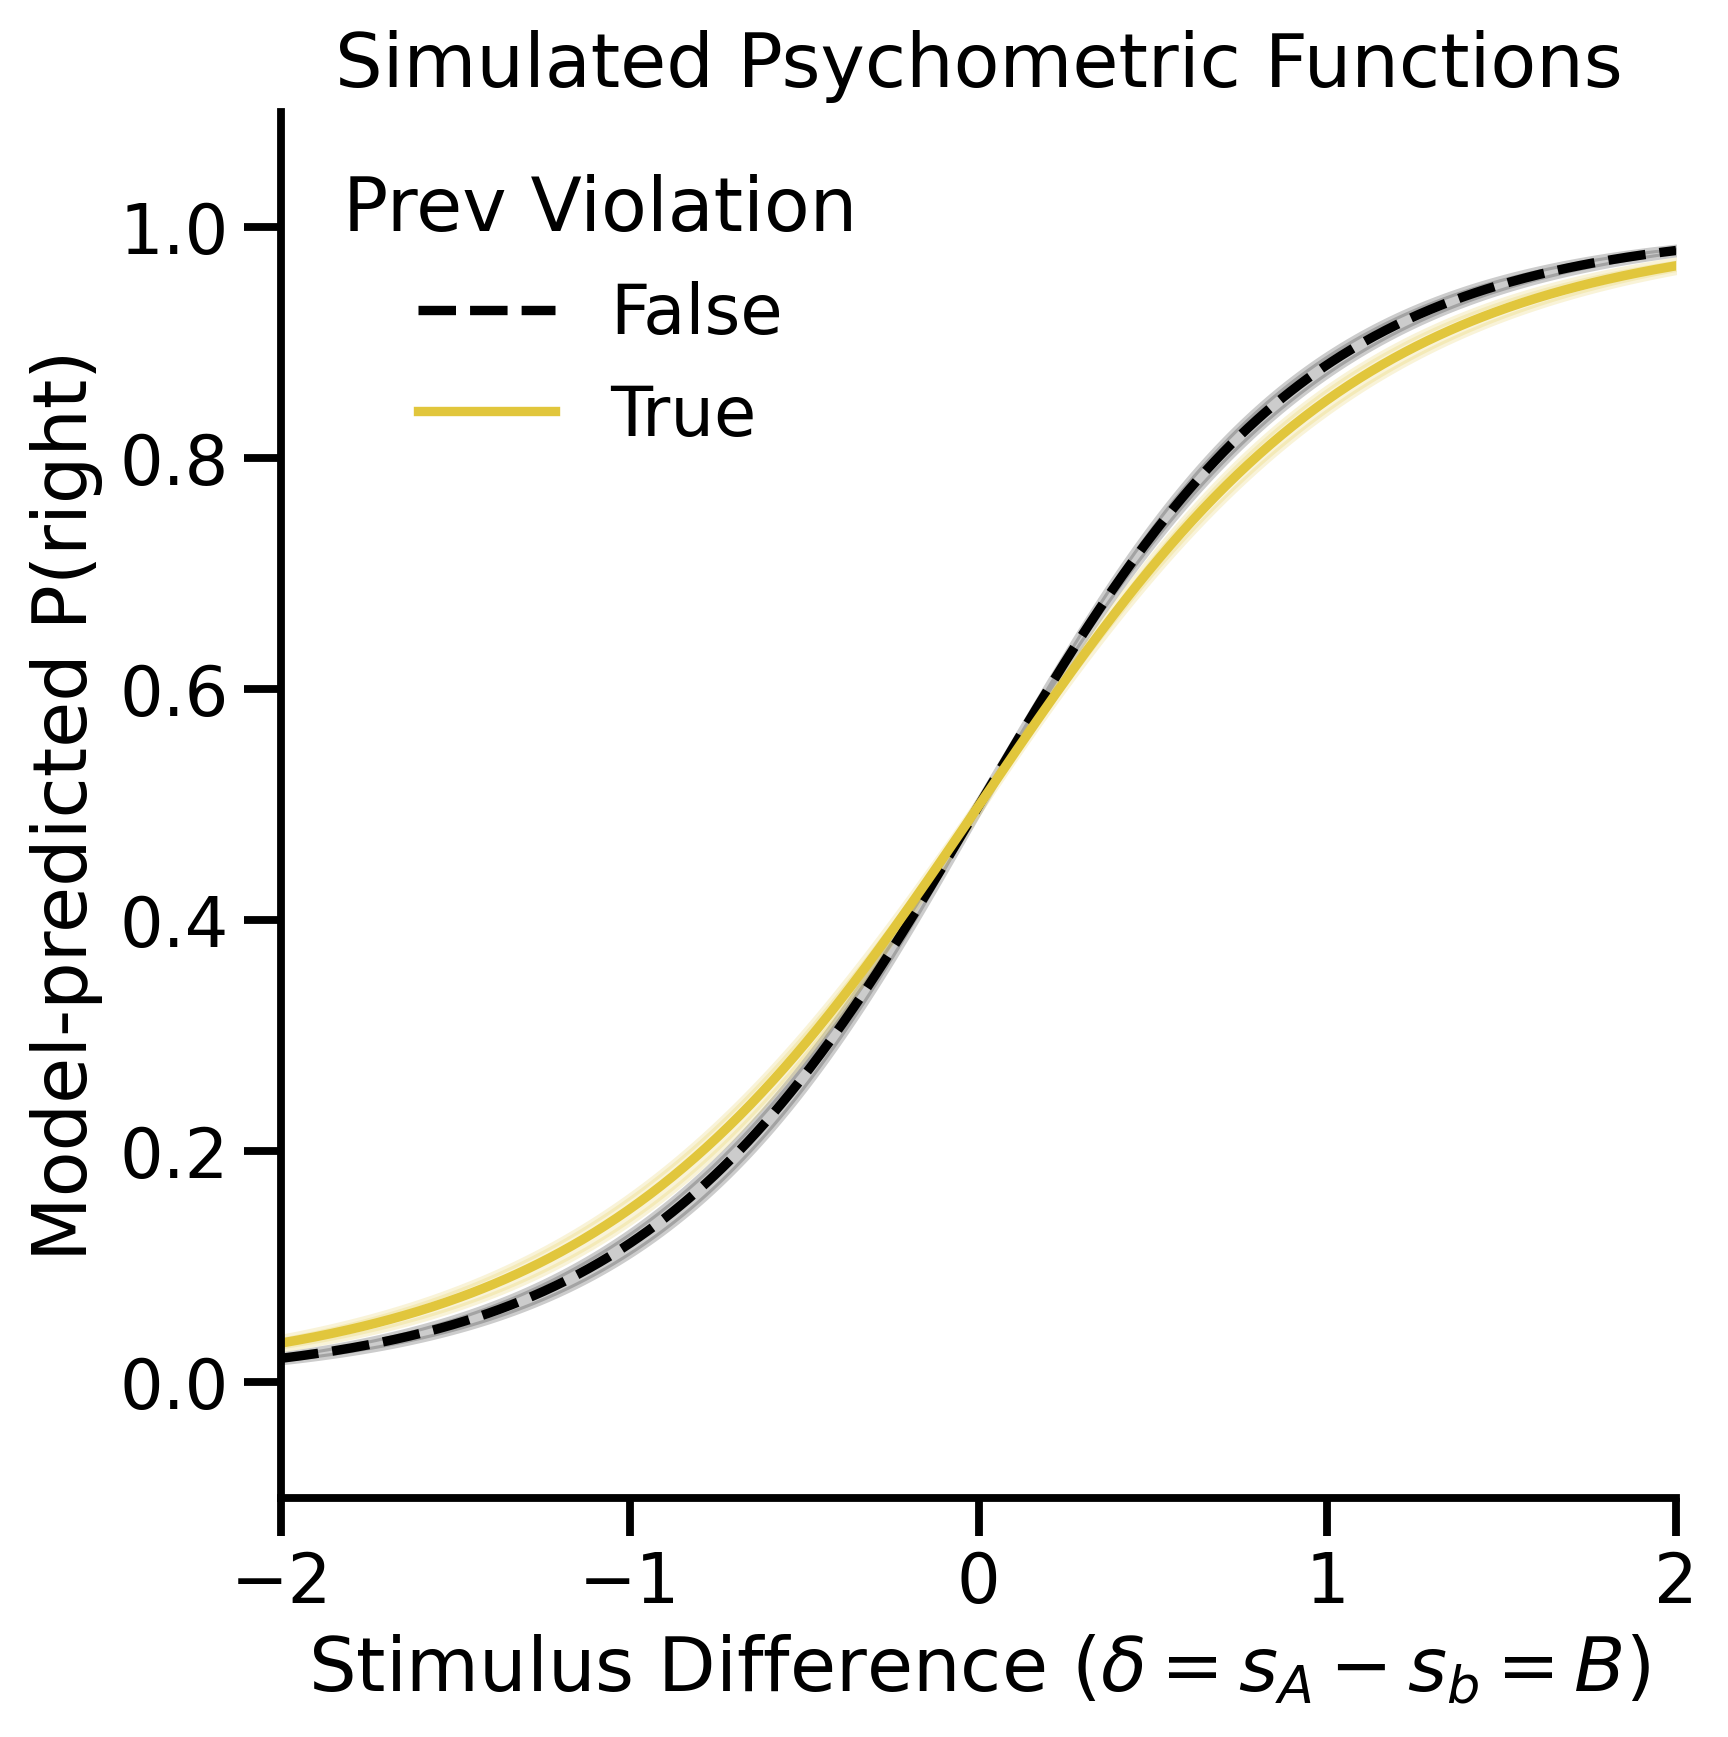

In [ ]:
plot_curves = curves.rename(columns={"previous_violation": "v_x"})
fig, ax = plt.subplots(figsize=(6, 6))
sns.despine()
sns.lineplot(
    data=plot_curves,
    x="delta",
    y="p_right",
    hue="v_x",
    style="v_x",
    palette=PSYCH_PALETTE,
    style_order=PSYCH_STYLE_ORDER,
    errorbar="se",
    ax=ax,
)
ax.set(
    title="Simulated Psychometric Functions",
    xlabel="Stimulus Difference ($\delta = s_A − s_b=B$)",
    ylabel="Model-predicted P(right)",
    ylim=(-0.1, 1.1),
    xlim=(-2, 2),
)
handles, labels = ax.get_legend_handles_labels()
labels = ["False" if label == "0" else "True" for label in labels]
ax.legend(handles, labels, title="Prev Violation", frameon=False)
save_figure(fig, "fig04c_simulated_psychometrics")

## Panel D — Stimulus sensitivity

Slope at δ = 0 from the binary-interaction simulation (Revision 1 title/ylabel).

16 subjects/replicates:
 • Not Prev Violation: mean = 0.513, SD = 0.105
 • Prev Violation: mean = 0.444, SD = 0.091

Shapiro–Wilk: W = 0.886, p = 0.049
Wilcoxon signed-rank: W = 6.0, p = 0.00042724609375


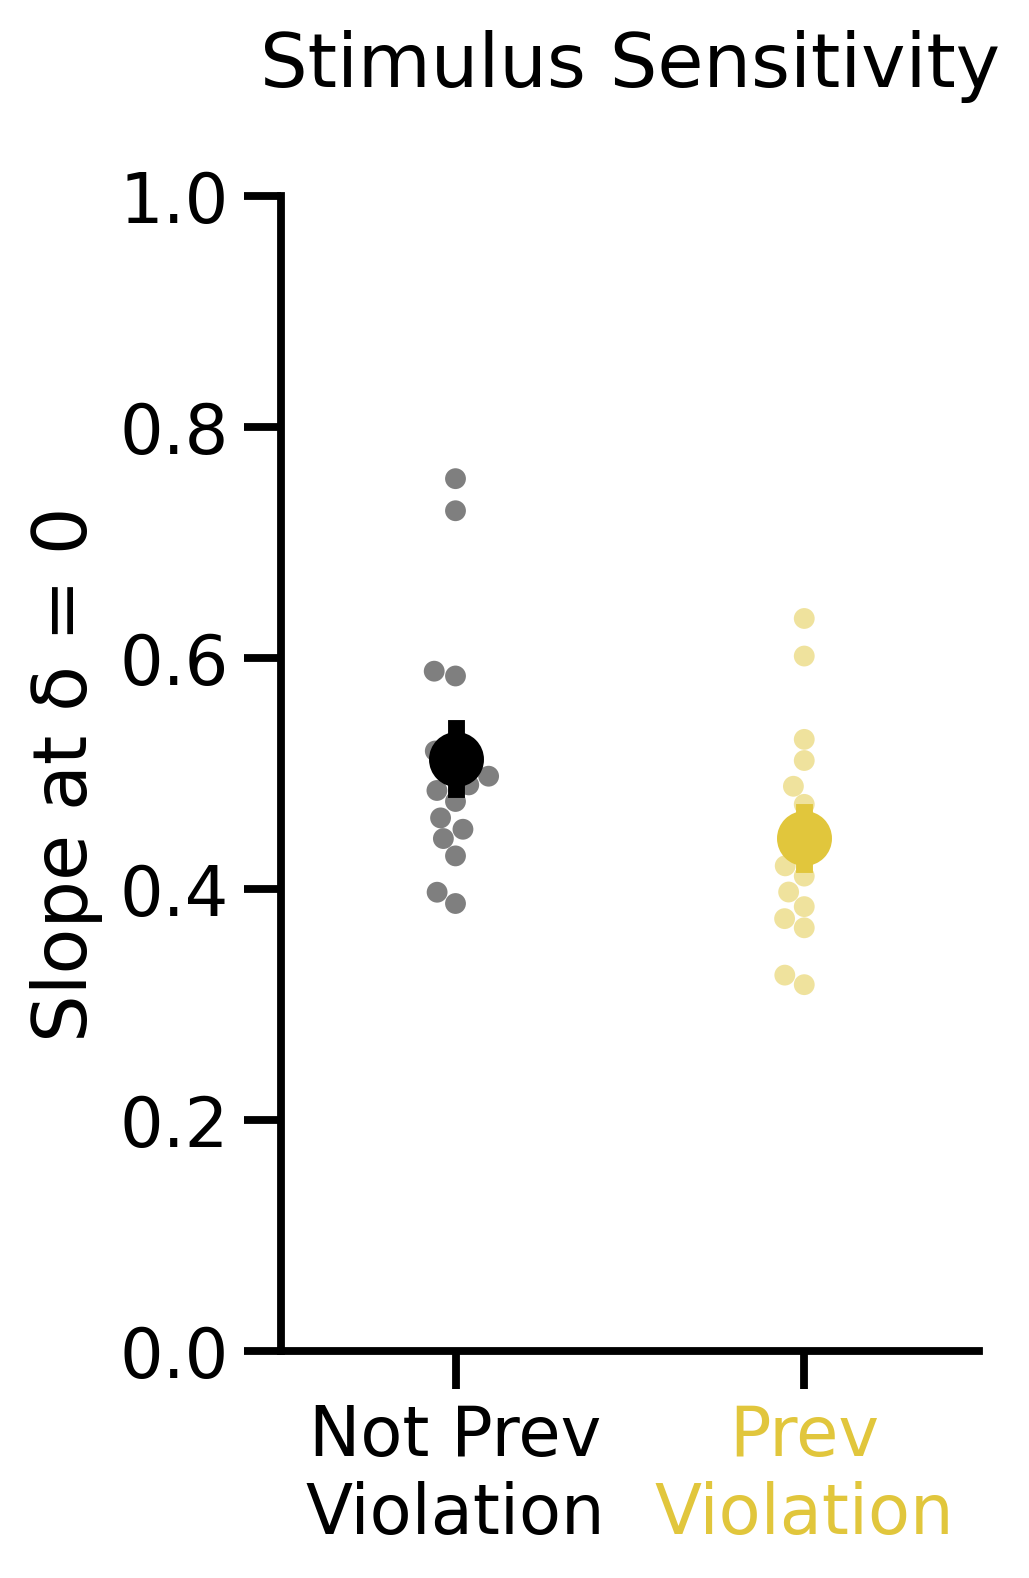

In [11]:
plot_df = metrics_melted.query("metric == 'slope'").copy()
plot_df["prev_violation"] = plot_df["prev_violation"].map(
    {0: "False", 1: "True"})

fig, ax = plt.subplots(figsize=(3, 5))
sns.pointplot(
    data=plot_df,
    x="prev_violation",
    y="value",
    hue="prev_violation",
    palette=PSYCH_PALETTE,
    ax=ax,
    linestyle="none",
    errorbar="se",
)
sns.swarmplot(
    data=plot_df,
    x="prev_violation",
    y="value",
    hue="prev_violation",
    palette=PSYCH_PALETTE,
    ax=ax,
    alpha=0.5,
)
ax.set_xticks(range(2))
ax.set_xticklabels(["Not Prev\nViolation", "Prev\nViolation"])
for label, color in zip(ax.get_xticklabels(), ["k", VIOLATION_COLOR]):
    label.set_color(color)
legend = ax.get_legend()
if legend is not None:
    legend.remove()
sns.despine()
ax.set_title("Stimulus Sensitivity\n")
ax.set(ylabel="Slope at δ = 0", xlabel="", ylim=(0, 1))
save_figure(fig, "fig04d_stimulus_sensitivity")

slope_stats = within_subject_test(
    metrics_melted.query("metric == 'slope'"),
    subject_col="animal_id",
    condition_col="prev_violation",
    value_col="value",
    condition_labels=CONDITION_LABELS,
)

## Panel E — Combined lapse rate

Lower + upper lapse from the binary-interaction simulation (Revision 1 title/ylabel; spelling corrected).

16 subjects/replicates:
 • Not Prev Violation: mean = 0.041, SD = 0.023
 • Prev Violation: mean = 0.067, SD = 0.040

Shapiro–Wilk: W = 0.944, p = 0.396
Paired t-test: t = 4.682545213596726, p = 0.0002946985944061351


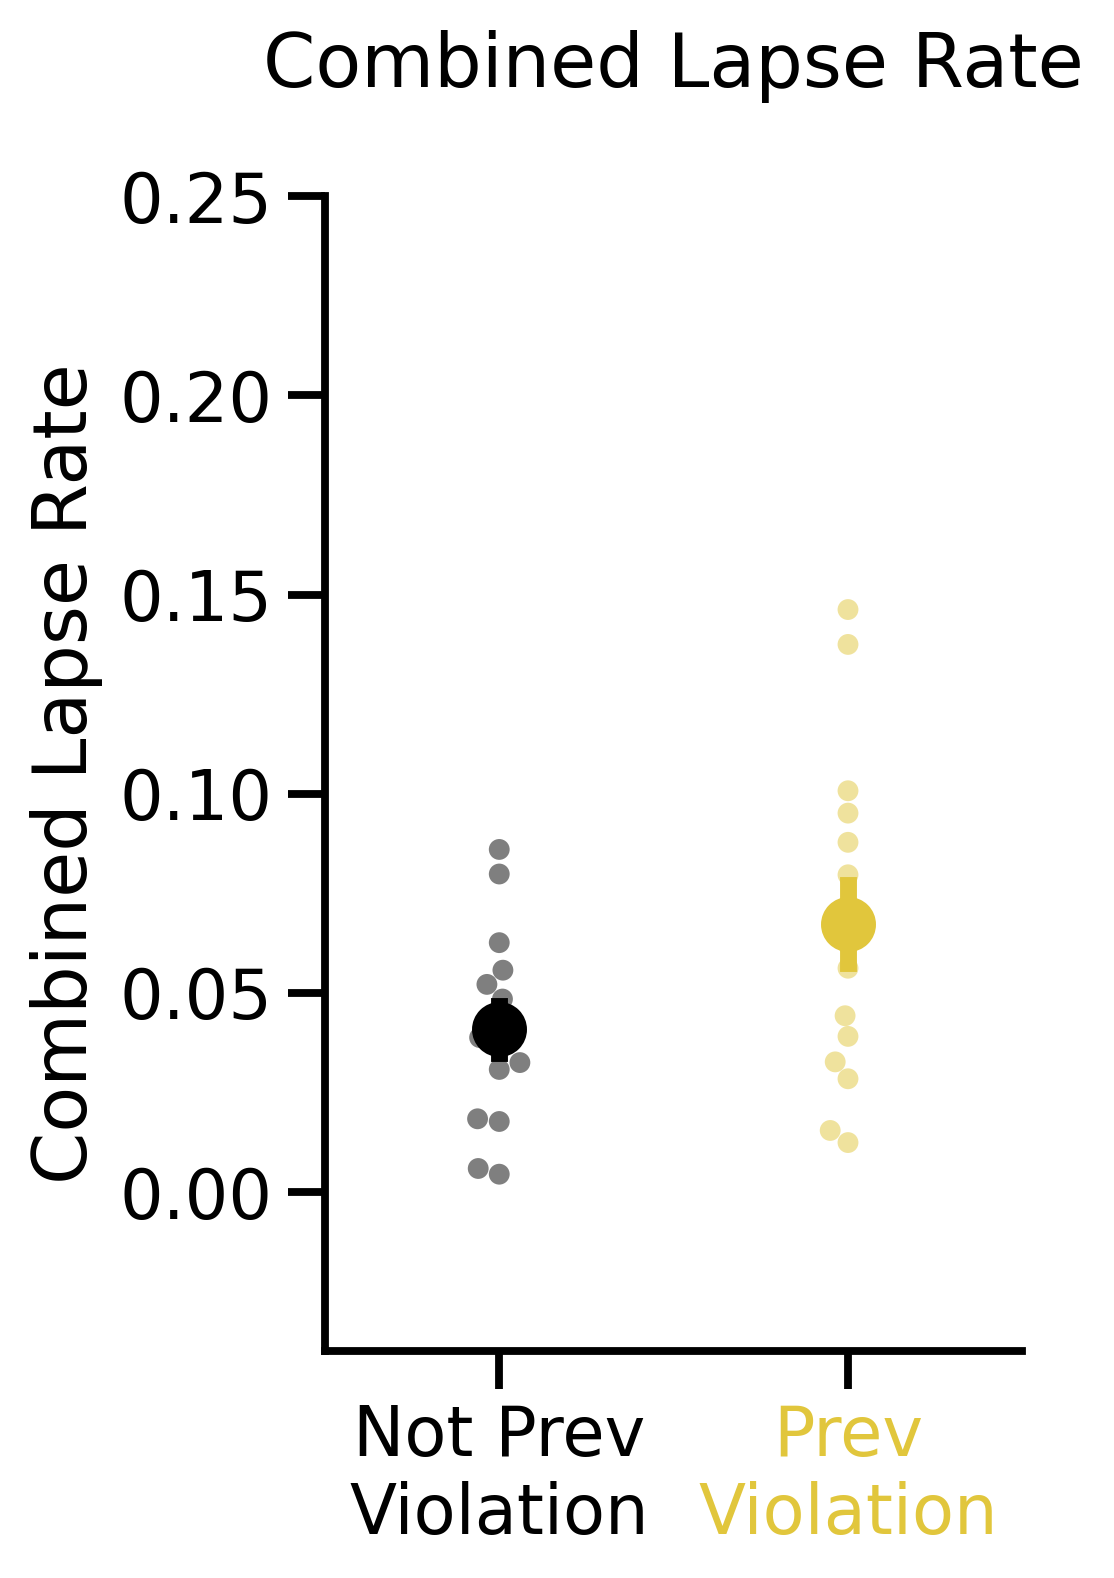

In [12]:
plot_df = metrics_melted.query("metric == 'combined_lapse'").copy()
plot_df["prev_violation"] = plot_df["prev_violation"].map(
    {0: "False", 1: "True"})

fig, ax = plt.subplots(figsize=(3, 5))
sns.pointplot(
    data=plot_df,
    x="prev_violation",
    y="value",
    hue="prev_violation",
    palette=PSYCH_PALETTE,
    ax=ax,
    linestyle="none",
    errorbar="se",
)
sns.swarmplot(
    data=plot_df,
    x="prev_violation",
    y="value",
    hue="prev_violation",
    palette=PSYCH_PALETTE,
    ax=ax,
    alpha=0.5,
)
ax.set_xticks(range(2))
ax.set_xticklabels(["Not Prev\nViolation", "Prev\nViolation"])
for label, color in zip(ax.get_xticklabels(), ["k", VIOLATION_COLOR]):
    label.set_color(color)
legend = ax.get_legend()
if legend is not None:
    legend.remove()
sns.despine()
ax.set_title("Combined Lapse Rate\n")
ax.set(ylabel="Combined Lapse Rate", xlabel="", ylim=(-0.04, 0.25))
save_figure(fig, "fig04e_combined_lapse_rate")

lapse_stats = within_subject_test(
    metrics_melted.query("metric == 'combined_lapse'"),
    subject_col="animal_id",
    condition_col="prev_violation",
    value_col="value",
    condition_labels=CONDITION_LABELS,
)